# As features distinguem LIDC de LNDb?

Comparar as distribuições das mesmas features de círculos de 6 mm nos dois datasets. Para reduzir diferenças de composição, emparelhar nódulos pela classe de malignidade e pelo diâmetro aproximado. Depois, testar se um modelo consegue identificar de que dataset vem um nódulo apenas pelas suas features radiomics e se retirar as features mais diferentes ajuda a prever malignidade.

Excluir as cópias de CT confirmadas no LNDb. O emparelhamento não elimina diferenças de aquisição ou anotação.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from scipy.stats import ks_2samp
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "configs/paths.yaml").exists(), "Executar na raiz do projeto ou em notebooks/."
sys.path.insert(0, str(ROOT))

from src.modeling import TARGET, load_data
from src.radiomics_extraction import load_paths

paths = load_paths(ROOT / "configs/paths.yaml")
lidc, features = load_data(ROOT / "data/lidc_circle_r6_hu.csv", "lidc", paths=paths)
lndb, lndb_features = load_data(
    ROOT / "data/lndb_circle_r6_hu.csv", "lndb",
    paths=paths, exclude_duplicate_lndb=True,
)
assert features == lndb_features

lidc_keys = ["patient_id", "series_uid", "nodule_id"]
lndb_keys = ["LNDbID", "FindingID"]
annotations = pd.read_csv(paths["lidc"]["annotations"], usecols=lidc_keys + ["volume"])
annotations["diameter_mm"] = 2 * np.cbrt(3 * annotations["volume"] / (4 * np.pi))
lidc_sizes = annotations.groupby(lidc_keys, as_index=False)["diameter_mm"].mean()
lidc = lidc.merge(lidc_sizes, on=lidc_keys, validate="one_to_one")
lndb_sizes = pd.read_csv(
    paths["lndb"]["findings"], usecols=lndb_keys + ["DiamEq_Rad"]
).rename(columns={"DiamEq_Rad": "diameter_mm"})
lndb = lndb.merge(lndb_sizes, on=lndb_keys, validate="one_to_one")
assert lidc["diameter_mm"].notna().all() and lndb["diameter_mm"].notna().all()
print(f"LIDC: {len(lidc)} nódulos | LNDb: {len(lndb)} nódulos | {len(features)} features comuns")

LIDC: 2637 nódulos | LNDb: 728 nódulos | 930 features comuns


## 1. Distribuições e diferenças

Dentro de cada classe, associar nódulos com diâmetros próximos sem reutilização. A estatística KS mede a maior distância entre as distribuições acumuladas de cada feature: 0 indica distribuições iguais, 1 indica separação completa. A tabela e os gráficos são descritivos, não identificam a causa das diferenças.

In [2]:
def match_by_class_and_diameter(lidc_rows, lndb_rows):
    left_indices, right_indices, gaps = [], [], []
    for label in range(1, 6):
        left = lidc_rows[lidc_rows[TARGET].eq(label)]
        right = lndb_rows[lndb_rows[TARGET].eq(label)]
        if left.empty or right.empty:
            continue
        distance = np.abs(
            left["diameter_mm"].to_numpy()[:, None]
            - right["diameter_mm"].to_numpy()[None, :]
        )
        i, j = linear_sum_assignment(distance)
        left_indices.extend(left.iloc[i].index)
        right_indices.extend(right.iloc[j].index)
        gaps.extend(distance[i, j])
    return (lidc_rows.loc[left_indices], lndb_rows.loc[right_indices],
            np.asarray(gaps))

matched_lidc, matched_lndb, gaps = match_by_class_and_diameter(lidc, lndb)
print(f"Nódulos emparelhados por dataset: {len(matched_lidc)}")
print(f"Diferença mediana de diâmetro: {np.median(gaps):.2f} mm | percentil 90: {np.quantile(gaps, 0.9):.2f} mm")
display(pd.DataFrame({
    "LIDC": matched_lidc[TARGET].value_counts().sort_index(),
    "LNDb": matched_lndb[TARGET].value_counts().sort_index(),
}).rename_axis("classe"))

differences = []
for feature in features:
    left = matched_lidc[feature].dropna().to_numpy()
    right = matched_lndb[feature].dropna().to_numpy()
    differences.append({
        "feature": feature,
        "mediana LIDC": np.median(left) if len(left) else np.nan,
        "mediana LNDb": np.median(right) if len(right) else np.nan,
        "KS": ks_2samp(left, right).statistic if len(left) and len(right) else np.nan,
        "missing LIDC": 1 - len(left) / len(matched_lidc),
        "missing LNDb": 1 - len(right) / len(matched_lndb),
    })
differences = pd.DataFrame(differences).sort_values("KS", ascending=False)
display(differences.head(20).round(3))

Nódulos emparelhados por dataset: 728
Diferença mediana de diâmetro: 0.01 mm | percentil 90: 1.43 mm


,LIDC,LNDb
classe,,
1,206,206
2,244,244
3,195,195
4,67,67
5,16,16


,feature,mediana LIDC,mediana LNDb,KS,missing LIDC,missing LNDb
325,wavelet-HH_glrlm_LongRunEmphasis,3.525,1.516,0.695,0.0,0.0
307,wavelet-HH_glcm_Idm,0.671,0.348,0.694,0.0,0.0
306,wavelet-HH_glcm_Id,0.685,0.426,0.692,0.0,0.0
303,wavelet-HH_glcm_DifferenceAverage,0.725,2.379,0.692,0.0,0.0
334,wavelet-HH_glrlm_ShortRunEmphasis,0.690,0.900,0.691,0.0,0.0
351,wavelet-HH_glszm_ZonePercentage,0.130,0.557,0.691,0.0,0.0
333,wavelet-HH_glrlm_RunVariance,0.941,0.186,0.691,0.0,0.0
330,wavelet-HH_glrlm_RunLengthNonUniformity,67.399,154.681,0.691,0.0,0.0
331,wavelet-HH_glrlm_RunLengthNonUniformityNormalized,0.463,0.771,0.690,0.0,0.0
332,wavelet-HH_glrlm_RunPercentage,0.626,0.868,0.690,0.0,0.0


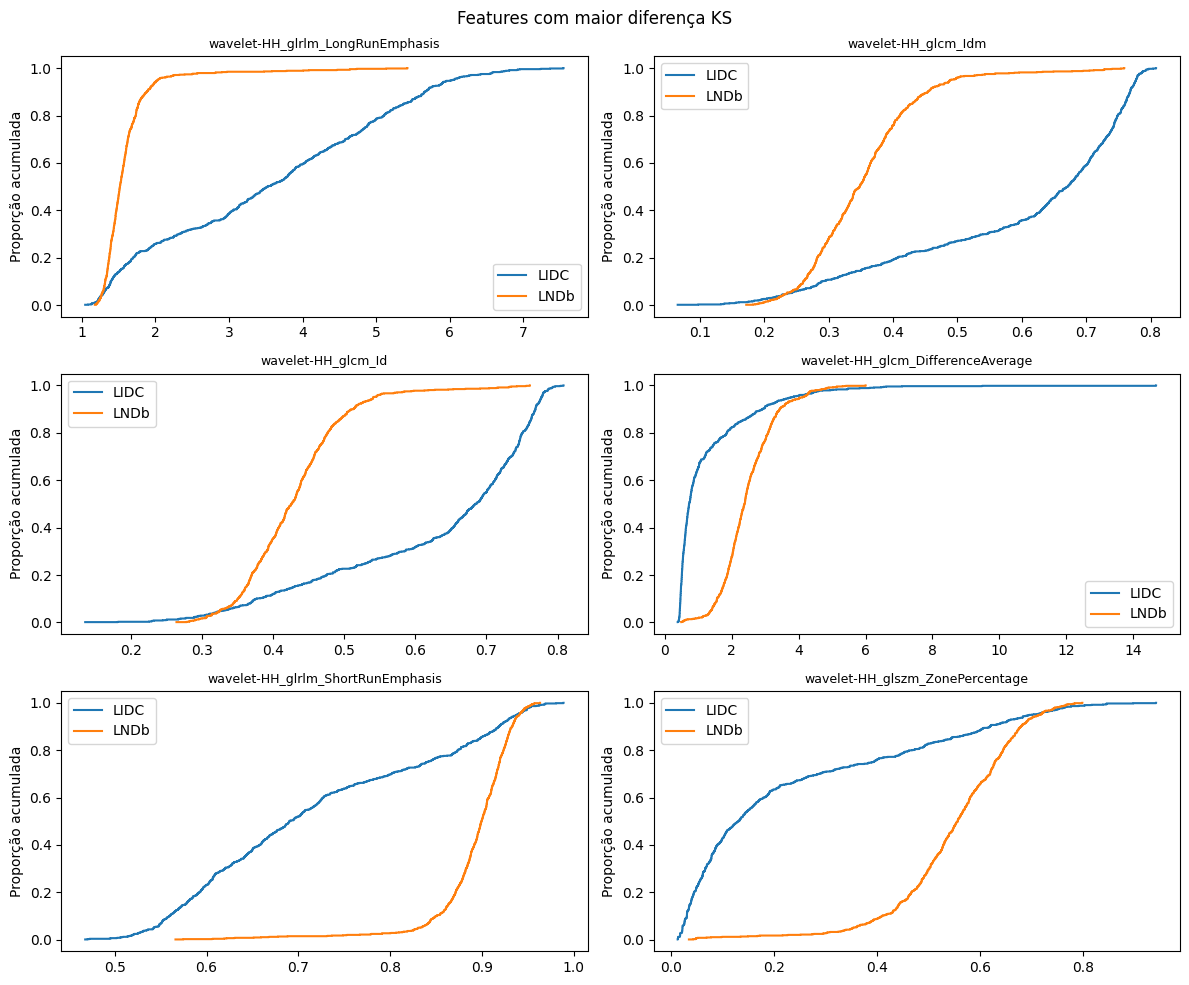

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(12, 10))
for ax, feature in zip(axes.flat, differences.head(6)["feature"]):
    for name, rows in [("LIDC", matched_lidc), ("LNDb", matched_lndb)]:
        values = np.sort(rows[feature].dropna().to_numpy())
        ax.step(values, np.arange(1, len(values) + 1) / len(values),
                where="post", label=name)
    ax.set_title(feature, fontsize=9)
    ax.set_ylabel("Proporção acumulada")
    ax.legend()
fig.suptitle("Features com maior diferença KS")
fig.tight_layout()
plt.show()

## 2. Um modelo consegue identificar o dataset?

RF com todas as features radiomics, sem classe ou diâmetro como entradas. Dividir por paciente/scan antes de emparelhar separadamente treino e teste em cada fold. A imputação é ajustada apenas no treino. AUC 0,5 corresponde a discriminação aleatória e AUC 1 a separação perfeita. Um bom resultado mostra diferenças entre datasets, não demonstra que sejam a causa do fraco desempenho na previsão de malignidade.

In [4]:
lidc_domain = lidc.assign(source=0, patient_group="LIDC:" + lidc["patient_id"].astype(str))
lndb_domain = lndb.assign(source=1, patient_group="LNDb:" + lndb["LNDbID"].astype(str))
domain_data = pd.concat([lidc_domain, lndb_domain], ignore_index=True)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
fold_results, heldout_predictions = [], []
for fold, (train_idx, test_idx) in enumerate(
    cv.split(domain_data, domain_data["source"], groups=domain_data["patient_group"]), start=1
):
    train = domain_data.iloc[train_idx]
    test = domain_data.iloc[test_idx]
    train_lidc, train_lndb, _ = match_by_class_and_diameter(
        train[train["source"].eq(0)], train[train["source"].eq(1)]
    )
    test_lidc, test_lndb, _ = match_by_class_and_diameter(
        test[test["source"].eq(0)], test[test["source"].eq(1)]
    )
    training = pd.concat([train_lidc, train_lndb], ignore_index=True)
    heldout = pd.concat([test_lidc, test_lndb], ignore_index=True)
    assert set(training["patient_group"]).isdisjoint(heldout["patient_group"])
    model = make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        RandomForestClassifier(n_estimators=200, class_weight="balanced",
                               random_state=42, n_jobs=-1),
    )
    model.fit(training[features], training["source"])
    probabilities = model.predict_proba(heldout[features])[:, 1]
    labels = heldout["source"].to_numpy()
    heldout_predictions.append(pd.DataFrame({
        "fold": fold, "source": labels, "probabilidade LNDb": probabilities,
    }))
    fold_results.append({
        "fold": fold, "treino por dataset": len(train_lidc),
        "teste por dataset": len(test_lidc),
        "AUC": roc_auc_score(labels, probabilities),
        "balanced accuracy": balanced_accuracy_score(labels, probabilities >= 0.5),
    })
    print(f"Fold {fold} concluído")

display(pd.DataFrame(fold_results).round(3))
heldout_predictions = pd.concat(heldout_predictions, ignore_index=True)
labels = heldout_predictions["source"]
probabilities = heldout_predictions["probabilidade LNDb"]
print(f"AUC global: {roc_auc_score(labels, probabilities):.3f}")
print(f"Balanced accuracy global: {balanced_accuracy_score(labels, probabilities >= 0.5):.3f}")
display(pd.DataFrame(
    confusion_matrix(labels, probabilities >= 0.5, labels=[0, 1]),
    index=["LIDC real", "LNDb real"],
    columns=["LIDC previsto", "LNDb previsto"],
))

Fold 1 concluído
Fold 2 concluído
Fold 3 concluído
Fold 4 concluído
Fold 5 concluído


,fold,treino por dataset,teste por dataset,AUC,balanced accuracy
0,1,574,154,0.993,0.942
1,2,560,159,0.979,0.931
2,3,598,130,0.948,0.900
3,4,582,146,0.993,0.959
4,5,598,130,0.921,0.858


AUC global: 0.967
Balanced accuracy global: 0.920


,LIDC previsto,LNDb previsto
LIDC real,640,79
LNDb real,36,683


## 3. As diferenças entre datasets prejudicam a previsão?

A AUC da secção anterior pertence a um modelo que prevê **LIDC ou LNDb**, não a um modelo de malignidade. Não sabemos ainda se as diferenças que encontrou prejudicam a previsão de malignidade.

Treinamos o mesmo RF de malignidade com todas as features, sem as 100 com maior diferença KS e sem outras 100 escolhidas ao acaso. Esta última versão verifica se uma eventual melhoria se deve apenas a usar menos features. Comparamos as três versões **nos mesmos nódulos reservados de LIDC e LNDb**. As features com maior KS são escolhidas apenas no treino de cada fold. Também voltamos a medir se as features restantes permitem identificar o dataset.

In [5]:
from src.modeling import make_model, metrics

n_removed = 100
comparisons = []

def matched_rows(rows):
    left, right, _ = match_by_class_and_diameter(
        rows[rows["source"].eq(0)], rows[rows["source"].eq(1)]
    )
    return pd.concat([left, right], ignore_index=True)

for fold, (train_idx, test_idx) in enumerate(
    cv.split(domain_data, domain_data["source"], groups=domain_data["patient_group"]), start=1
):
    training = matched_rows(domain_data.iloc[train_idx])
    heldout = matched_rows(domain_data.iloc[test_idx])
    assert set(training["patient_group"]).isdisjoint(heldout["patient_group"])
    train_lidc = training[training["source"].eq(0)]
    train_lndb = training[training["source"].eq(1)]

    def training_ks(feature):
        left = train_lidc[feature].dropna()
        right = train_lndb[feature].dropna()
        return ks_2samp(left, right).statistic if len(left) and len(right) else -1

    high_ks = set(sorted(features, key=training_ks, reverse=True)[:n_removed])
    remaining = [feature for feature in features if feature not in high_ks]
    random_removed = set(np.random.default_rng(42 + fold).choice(
        remaining, size=n_removed, replace=False
    ))
    feature_sets = {
        "Todas": features,
        "Sem top 100 KS": remaining,
        "Sem 100 aleatórias": [feature for feature in features if feature not in random_removed],
    }

    for name, selected in feature_sets.items():
        malignancy_model = make_model(class_weight="balanced")
        malignancy_model.fit(training[selected], training[TARGET])
        domain_model = make_pipeline(
            SimpleImputer(strategy="median", keep_empty_features=True),
            RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                   random_state=42, n_jobs=-1),
        )
        domain_model.fit(training[selected], training["source"])
        comparisons.append(heldout[["source", TARGET]].assign(
            fold=fold, features=name,
            malignancy_prediction=malignancy_model.predict(heldout[selected]),
            lndb_probability=domain_model.predict_proba(heldout[selected])[:, 1],
        ))
    print(f"Fold {fold} concluído")

comparisons = pd.concat(comparisons, ignore_index=True)

Fold 1 concluído
Fold 2 concluído
Fold 3 concluído
Fold 4 concluído
Fold 5 concluído


In [6]:
domain_scores = pd.DataFrame([
    {"features": name, "AUC origem": roc_auc_score(rows["source"], rows["lndb_probability"])}
    for name, rows in comparisons.groupby("features", sort=False)
])
display(domain_scores.round(3))

malignancy_scores = pd.DataFrame([
    {"features": name, "dataset": {0: "LIDC", 1: "LNDb"}[source],
     "nodules": len(rows), **metrics(rows[TARGET], rows["malignancy_prediction"])}
    for (name, source), rows in comparisons.groupby(["features", "source"], sort=False)
])
display(malignancy_scores.round(3))

,features,AUC origem
0,Todas,0.967
1,Sem top 100 KS,0.966
2,Sem 100 aleatórias,0.963


,features,dataset,nodules,balanced_accuracy,macro_f1,qwk,mae
0,Todas,LIDC,719,0.352,0.364,0.534,0.620
1,Todas,LNDb,719,0.374,0.378,0.433,0.698
2,Sem top 100 KS,LIDC,719,0.358,0.373,0.542,0.616
3,Sem top 100 KS,LNDb,719,0.375,0.377,0.444,0.693
4,Sem 100 aleatórias,LIDC,719,0.346,0.358,0.531,0.618
5,Sem 100 aleatórias,LNDb,719,0.379,0.385,0.427,0.702


Se a AUC de origem baixar mas a classificação de malignidade não melhorar, as diferenças entre datasets existem, mas este teste não mostra que prejudiquem o modelo de malignidade. Se retirar as features com maior KS melhorar a classificação nos nódulos reservados mais do que retirar features ao acaso, isso sugere que aquelas features a prejudicavam. **Não prova** que o modelo aprendia a origem dos nódulos nem que as diferenças tenham uma causa específica.

Com os dados atuais, a AUC de origem é 0,967 com todas as features, 0,966 sem as 100 com maior KS e 0,963 sem as 100 aleatórias. Retirar estas 100 features de maior KS não elimina a informação sobre o dataset. As métricas de malignidade mudam pouco e não mostram uma melhoria consistente nos dois datasets.

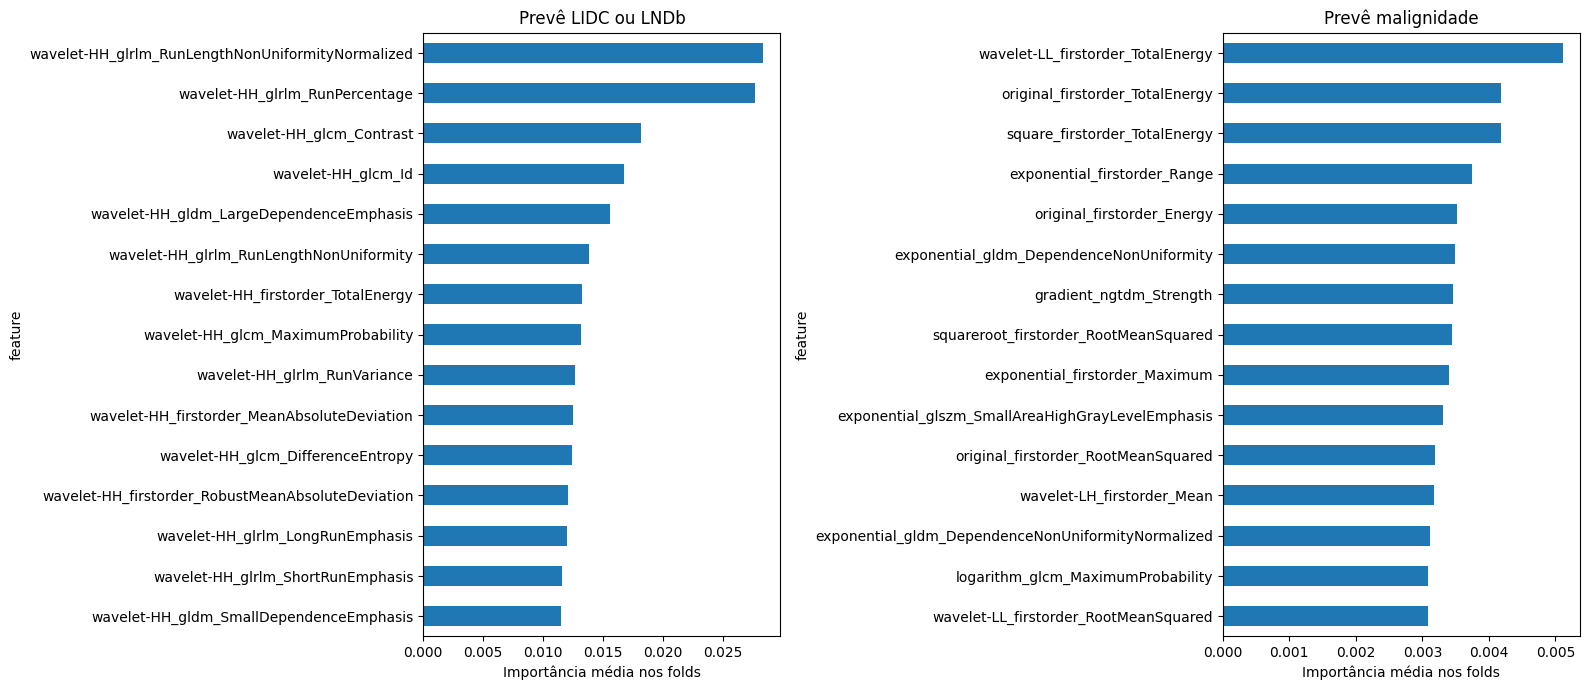

In [7]:
from src.modeling import make_model

importances = []

for fold, (train_idx, _) in enumerate(
    cv.split(
        domain_data,
        domain_data["source"],
        groups=domain_data["patient_group"],
    ),
    start=1,
):
    train = domain_data.iloc[train_idx]
    train_lidc, train_lndb, _ = match_by_class_and_diameter(
        train[train["source"].eq(0)],
        train[train["source"].eq(1)],
    )
    matched = pd.concat([train_lidc, train_lndb], ignore_index=True)

    origin_rf = make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1,
        ),
    )
    origin_rf.fit(matched[features], matched["source"])

    malignancy_rf = make_model(class_weight="balanced")
    malignancy_rf.fit(matched[features], matched[TARGET])

    importances.append(pd.DataFrame({
        "feature": features,
        "fold": fold,
        "origem": origin_rf.named_steps[
            "randomforestclassifier"
        ].feature_importances_,
        "malignidade": malignancy_rf.named_steps[
            "randomforestclassifier"
        ].feature_importances_,
    }))

mean_importance = (
    pd.concat(importances)
    .groupby("feature")[["origem", "malignidade"]]
    .mean()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, column, title in zip(
    axes,
    ["origem", "malignidade"],
    ["Prevê LIDC ou LNDb", "Prevê malignidade"],
):
    mean_importance[column].nlargest(15).sort_values().plot.barh(ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Importância média nos folds")

fig.tight_layout()
plt.show()